# TP Final InfoVis — Punto 1: Exploración de la API del Banco Mundial

Dos APIs: Data360 (nueva, https://data360api.worldbank.org) y la v2 clásica (https://api.worldbank.org/v2) para metadata de países.

In [1]:
import requests
import pandas as pd

DATA360_ROOT = "https://data360api.worldbank.org"
V2_ROOT = "https://api.worldbank.org/v2"


## 1.1 — Qué bases de datos existen

In [2]:
resp = requests.post(f"{DATA360_ROOT}/data360/searchv2", json={
    "count": True,
    "search": "*",
    "top": 0,
    "facets": ["series_description/database_id,count:200"]
})
resp.raise_for_status()
facets = resp.json()["@search.facets"]["series_description/database_id"]

databases = pd.DataFrame(facets).rename(columns={"value": "database_id", "count": "n_indicadores"})
print(f"Total de bases de datos encontradas: {len(databases)}")
print(f"Total de indicadores en el catalogo: {databases['n_indicadores'].sum()}")
databases.head(20)


Total de bases de datos encontradas: 166
Total de indicadores en el catalogo: 9958


,database_id,n_indicadores
0,WB_WDI,1546
1,IMF_BOP,1147
2,WB_EDSTATS,1073
3,WB_ES,585
4,IMF_IFS,496
5,WB_GS,364
6,WB_FINDEX,281
7,IMF_GFS_SOO,219
8,BS_SGI,194
9,WB_HNP,193


Bases de datos más grandes: WB_WDI, IMF_BOP, WB_EDSTATS, WB_ES, IMF_IFS, WB_FINDEX, WEF_GCI, WB_CCKP, entre otras.

## 1.2 — Qué indicadores están disponibles

In [3]:
resp = requests.get(f"{DATA360_ROOT}/data360/indicators", params={"datasetId": "WB_WDI"})
resp.raise_for_status()
indicadores_wdi = resp.json()
print(f"WB_WDI tiene {len(indicadores_wdi)} indicadores")
indicadores_wdi[:10]


WB_WDI tiene 1499 indicadores


['WB_WDI_BN_KAC_EOMS_CD',
 'WB_WDI_BN_RES_INCL_CD',
 'WB_WDI_BX_PEF_TOTL_CD_WD',
 'WB_WDI_BX_TRF_PWKR_DT_GD_ZS',
 'WB_WDI_CM_MKT_INDX_ZG',
 'WB_WDI_DC_DAC_DNKL_CD',
 'WB_WDI_DC_DAC_NZLL_CD',
 'WB_WDI_DC_DAC_SWEL_CD',
 'WB_WDI_DC_ODA_TOTL_KD',
 'WB_WDI_DT_DOD_DECT_CD']

También se puede buscar por palabra clave en todo el catálogo con /data360/searchv2.

In [4]:
##CREO que esto lo sacaría

resp = requests.post(f"{DATA360_ROOT}/data360/searchv2", json={
    "count": True,
    "select": "series_description/idno, series_description/name, series_description/database_id",
    "search": "climate change",
    "top": 15
})
resp.raise_for_status()
data = resp.json()
print(f"Coincidencias totales: {data['@odata.count']}")

resultados = pd.json_normalize([r["series_description"] for r in data["value"]])
resultados


Coincidencias totales: 1985


,idno,name,database_id
0,IMF_CDIR_ECFRMH,Climate-Driven Hazard & Exposure,IMF_CDIR
1,None,United Republic of Tanzania - Country Climate ...,None
2,None,Egypt - Gender Equality and Climate Change : B...,None
3,TOOLS.CCKP,Climate Change Knowledge Portal,None
4,None,Malawi - Country Climate and Development Repor...,None
5,WB_CCKP_PRPERCNT,Precipitation Percent Change,WB_CCKP
6,None,Dominican Republic - Country Climate and Devel...,None
7,None,Philippines - Country Climate and Development ...,None
8,None,Malawi - Country Climate and Development Repor...,None
9,IMF_CDIR_ECFRMR,Climate-Driven Inform Risk Indicator,IMF_CDIR


## 1.3 — Cómo se estructuran los datos: metadata de un indicador (/data360/metadata)

In [5]:
#de ultima busquemos otro indicador

resp = requests.post(f"{DATA360_ROOT}/data360/metadata", json={
    "query": "&$filter=series_description/idno eq 'WB_WDI_SP_POP_TOTL'"
})
resp.raise_for_status()
meta = resp.json()["value"][0]["series_description"]

for campo in ["idno", "name", "database_id", "measurement_unit", "periodicity", "statistical_concept"]:
    print(f"{campo}: {meta[campo]}")

print("\ntopics (jerarquia tematica):")
for t in meta["topics"]:
    print(f"  - {t['name']}  (vocabulario: {t['vocabulary']})")


idno: WB_WDI_SP_POP_TOTL
name: Population, total
database_id: WB_WDI
measurement_unit: Unit
periodicity: Annual
statistical_concept: Estimates of total population describe the size of total population. Population estimates are dependent on the demographic components of change that are fertility, mortality and migration. As the size of population continues to change throughout the time even within a year, a reference time in the year that the estimate refers to is needed, such as mid-year, end-year or beginning of year. The values shown are midyear estimates.

topics (jerarquia tematica):
  - Infrastructure  (vocabulario: WB Practice Groups)
  - Urban, Resilience and Land  (vocabulario: Data360 Topic L1)
  - Housing  (vocabulario: Data360 Topic L2)


Datos observacionales (/data360/data), estándar SDMX: REF_AREA, TIME_PERIOD, FREQ, desagregaciones opcionales.

In [6]:
resp = requests.get(f"{DATA360_ROOT}/data360/data", params={
    "DATABASE_ID": "WB_WDI",
    "INDICATOR": "WB_WDI_SP_POP_TOTL",
    "REF_AREA": "ARG",
    "timePeriodFrom": "2015",
    "timePeriodTo": "2023",
})
resp.raise_for_status()
datos = pd.DataFrame(resp.json()["value"])
datos[["REF_AREA", "TIME_PERIOD", "OBS_VALUE", "UNIT_MEASURE", "FREQ"]].sort_values("TIME_PERIOD")


,REF_AREA,TIME_PERIOD,OBS_VALUE,UNIT_MEASURE,FREQ
1,ARG,2015,43477012,PS,A
0,ARG,2016,43900313,PS,A
7,ARG,2017,44288894,PS,A
2,ARG,2018,44654882,PS,A
6,ARG,2019,44973465,PS,A
8,ARG,2020,45191965,PS,A
5,ARG,2021,45312281,PS,A
4,ARG,2022,45407904,PS,A
3,ARG,2023,45538401,PS,A


Notas: paginado con skip (max 1000/req), desagregaciones vía /data360/disaggregation, países sin REF_AREA trae todos.

Catálogo de países: Data360 solo usa REF_AREA, la metadata de país se saca de la API v2 clásica.

In [7]:
resp = requests.get(f"{V2_ROOT}/country", params={"format": "json", "per_page": 400})
resp.raise_for_status()
_, countries_raw = resp.json()

countries = pd.json_normalize(countries_raw)
countries = countries[countries["region.value"] != "Aggregates"]  # sacar agregados regionales
print(f"Paises (sin agregados regionales): {len(countries)}")
countries[["id", "name", "region.value", "incomeLevel.value", "capitalCity"]].head(10)


Paises (sin agregados regionales): 217


,id,name,region.value,incomeLevel.value,capitalCity
0,ABW,Aruba,Latin America & Caribbean,High income,Oranjestad
2,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul
5,AGO,Angola,Sub-Saharan Africa,Lower middle income,Luanda
6,ALB,Albania,Europe & Central Asia,Upper middle income,Tirane
7,AND,Andorra,Europe & Central Asia,High income,Andorra la Vella
9,ARE,United Arab Emirates,"Middle East, North Africa, Afghanistan & Pakistan",High income,Abu Dhabi
10,ARG,Argentina,Latin America & Caribbean,Upper middle income,Buenos Aires
11,ARM,Armenia,Europe & Central Asia,Upper middle income,Yerevan
12,ASM,American Samoa,East Asia & Pacific,High income,Pago Pago
13,ATG,Antigua and Barbuda,Latin America & Caribbean,High income,Saint John's


## 1.4 — Análisis exploratorio con pandas

In [8]:
databases.describe()


,n_indicadores
count,166.000000
mean,59.987952
std,182.320164
min,1.000000
25%,4.000000
50%,10.000000
75%,37.000000
max,1546.000000


describe() sobre n_indicadores: distribución sesgada, WB_WDI concentra ~1500 indicadores.

In [9]:
databases.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166 entries, 0 to 165
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   database_id    166 non-null    object
 1   n_indicadores  166 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.7+ KB


Ejemplo con datos reales: población por país (2022).

In [10]:
resp = requests.get(f"{DATA360_ROOT}/data360/data", params={
    "DATABASE_ID": "WB_WDI",
    "INDICATOR": "WB_WDI_SP_POP_TOTL",
    "TIME_PERIOD": "2022",
})
resp.raise_for_status()
pob = pd.DataFrame(resp.json()["value"])
pob["OBS_VALUE"] = pd.to_numeric(pob["OBS_VALUE"], errors="coerce")
print(f"Filas totales (incluye agregados regionales como WLD, AFE, ARB): {len(pob)}")

# nos quedamos solo con paises reales (descartamos agregados) usando el catalogo de countries
pob_paises = pob.merge(
    countries[["id", "name", "region.value", "incomeLevel.value"]],
    left_on="REF_AREA", right_on="id"
)
print(f"Filas solo paises reales: {len(pob_paises)}")
pob_paises.head()


Filas totales (incluye agregados regionales como WLD, AFE, ARB): 264
Filas solo paises reales: 217


,OBS_VALUE,TIME_FORMAT,UNIT_MULT,COMMENT_OBS,OBS_STATUS,OBS_CONF,AGG_METHOD,DECIMALS,COMMENT_TS,DATA_SOURCE,...,COMP_BREAKDOWN_2,COMP_BREAKDOWN_3,TIME_PERIOD,FREQ,UNIT_MEASURE,UNIT_TYPE,id,name,region.value,incomeLevel.value
0,10074977,P1Y,0,None,A,PU,_Z,2,None,None,...,_Z,_Z,2022,A,PS,None,ARE,United Arab Emirates,"Middle East, North Africa, Afghanistan & Pakistan",High income
1,67636000,P1Y,0,None,A,PU,_Z,2,None,None,...,_Z,_Z,2022,A,PS,None,GBR,United Kingdom,Europe & Central Asia,High income
2,333996304,P1Y,0,None,A,PU,_Z,2,None,None,...,_Z,_Z,2022,A,PS,None,USA,United States,North America,High income
3,3390913,P1Y,0,None,A,PU,_Z,2,None,None,...,_Z,_Z,2022,A,PS,None,URY,Uruguay,Latin America & Caribbean,High income
4,34938955,P1Y,0,None,A,PU,_Z,2,None,None,...,_Z,_Z,2022,A,PS,None,UZB,Uzbekistan,Europe & Central Asia,Lower middle income


In [11]:
#este lo sacaría porque no entiendo jaja
pob_paises["OBS_VALUE"].describe()


,OBS_VALUE
count,2.170000e+02
mean,3.670675e+07
std,1.415287e+08
min,9.992000e+03
25%,8.216370e+05
50%,6.664449e+06
75%,2.601872e+07
max,1.425423e+09


Distribución asimétrica: mediana (~6.7M) muy por debajo de la media (~36.7M), arrastrada por India y China.

In [12]:
pob_paises.nlargest(10, "OBS_VALUE")[["name", "region.value", "OBS_VALUE"]]


,name,region.value,OBS_VALUE
54,India,South Asia,1425423212
113,China,East Asia & Pacific,1412175000
2,United States,North America,333996304
55,Indonesia,East Asia & Pacific,278830529
174,Pakistan,"Middle East, North Africa, Afghanistan & Pakistan",243700667
169,Nigeria,Sub-Saharan Africa,223150896
18,Brazil,Latin America & Caribbean,210306415
158,Bangladesh,South Asia,169384897
127,Russian Federation,Europe & Central Asia,144236933
40,Mexico,Latin America & Caribbean,128613117


In [13]:
pob_paises.groupby("region.value")["OBS_VALUE"].agg(["count", "sum", "mean", "median"]).sort_values("sum", ascending=False)


,count,sum,mean,median
region.value,,,,
East Asia & Pacific,37,2356430840,6.368732e+07,1369295.0
South Asia,6,1648009565,2.746683e+08,25948218.0
Sub-Saharan Africa,48,1228187451,2.558724e+07,13907319.0
Europe & Central Asia,58,924267385,1.593564e+07,5729571.5
"Middle East, North Africa, Afghanistan & Pakistan",23,782349366,3.401519e+07,11256263.0
Latin America & Caribbean,42,653108131,1.555019e+07,3029646.0
North America,3,373011185,1.243371e+08,38950132.0


info() para ver nulos en columnas de desagregación (SEX, AGE, etc.).

In [14]:
pob_paises.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 28 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   OBS_VALUE          217 non-null    int64 
 1   TIME_FORMAT        217 non-null    object
 2   UNIT_MULT          217 non-null    int64 
 3   COMMENT_OBS        0 non-null      object
 4   OBS_STATUS         217 non-null    object
 5   OBS_CONF           217 non-null    object
 6   AGG_METHOD         217 non-null    object
 7   DECIMALS           217 non-null    object
 8   COMMENT_TS         0 non-null      object
 9   DATA_SOURCE        0 non-null      object
 10  LATEST_DATA        217 non-null    bool  
 11  DATABASE_ID        217 non-null    object
 12  INDICATOR          217 non-null    object
 13  REF_AREA           217 non-null    object
 14  SEX                217 non-null    object
 15  AGE                217 non-null    object
 16  URBANISATION       217 non-null    object
 1

## 1.5 — Mismo punto 1, con las librerías del TP (duckdb, matplotlib, seaborn, altair)

In [15]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
import altair as alt


duckdb — consultas SQL directas sobre los DataFrames.

In [16]:
top10_db = duckdb.sql('''
    SELECT database_id, n_indicadores
    FROM databases
    ORDER BY n_indicadores DESC
    LIMIT 10
''').df()
top10_db


,database_id,n_indicadores
0,WB_WDI,1546
1,IMF_BOP,1147
2,WB_EDSTATS,1073
3,WB_ES,585
4,IMF_IFS,496
5,WB_GS,364
6,WB_FINDEX,281
7,IMF_GFS_SOO,219
8,BS_SGI,194
9,WB_HNP,193


matplotlib / seaborn — EDA estático rápido.

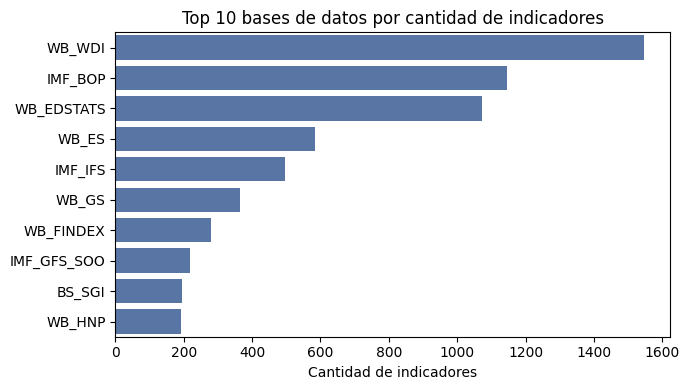

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=top10_db, y="database_id", x="n_indicadores", ax=ax, color="#4C72B0")
ax.set_title("Top 10 bases de datos por cantidad de indicadores")
ax.set_xlabel("Cantidad de indicadores")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


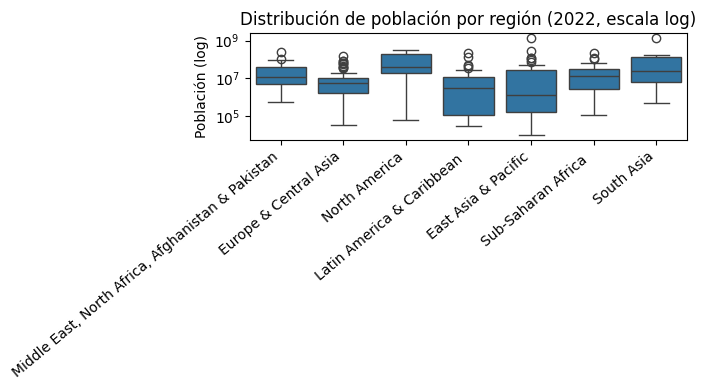

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=pob_paises, x="region.value", y="OBS_VALUE", ax=ax)
ax.set_yscale("log")
ax.set_title("Distribución de población por región (2022, escala log)")
ax.set_xlabel("")
ax.set_ylabel("Población (log)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()


altair — misma idea, pero interactiva (la librería del entregable final).

In [19]:
alt.Chart(pob_paises).mark_circle(size=60).encode(
    x=alt.X("region.value:N", title=None),
    y=alt.Y("OBS_VALUE:Q", scale=alt.Scale(type="log"), title="Población (log)"),
    color="region.value:N",
    tooltip=["name", "region.value", "OBS_VALUE"]
).properties(
    width=600, height=350,
    title="Población por país y región (2022) — interactivo: pasa el mouse"
).interactive()


alt.Chart(...)

Las 5 librerías de la consigna probadas end-to-end: pandas, duckdb, matplotlib/seaborn, altair.

## Resumen de la estructura de Data360: base de datos → indicador → país/área → tiempo → temática → desagregación → valor.

# Punto 2: Visualizaciones

Tema: ingreso y obesidad. LATAM con foco en Argentina.

In [20]:
import time

alt.data_transformers.disable_max_rows()


DataTransformerRegistry.enable('default')

## 2.1 — Funciones reutilizables

Generalizamos lo del Punto 1:
- `buscar_indicador`: busca por keyword en todo el catálogo y devuelve un DataFrame con `idno`, `name`, `database_id`.
- `obtener_serie`: trae una serie completa (todos los países, todos los años) paginando con `skip`, porque `/data360/data` devuelve máximo 1000 filas por llamada (ver nota 1.3 del Punto 1).

In [21]:
def buscar_indicador(keyword, top=20):
    resp = requests.post(f"{DATA360_ROOT}/data360/searchv2", json={
        "count": True,
        "select": "series_description/idno, series_description/name, series_description/database_id",
        "search": keyword,
        "top": top,
    })
    resp.raise_for_status()
    data = resp.json()
    resultados = pd.json_normalize([r["series_description"] for r in data["value"]])
    resultados = resultados.rename(columns={
        "idno": "idno", "name": "name", "database_id": "database_id"
    })
    return resultados


def obtener_serie(database_id, indicator_id, ref_area=None, time_period_from=None, time_period_to=None, pausa=0.2):
    """Trae una serie completa paginando con skip (max 1000 filas por request)."""
    filas = []
    skip = 0
    while True:
        params = {"DATABASE_ID": database_id, "INDICATOR": indicator_id, "skip": skip}
        if ref_area:
            params["REF_AREA"] = ref_area
        if time_period_from:
            params["timePeriodFrom"] = time_period_from
        if time_period_to:
            params["timePeriodTo"] = time_period_to

        resp = requests.get(f"{DATA360_ROOT}/data360/data", params=params)
        resp.raise_for_status()
        pagina = resp.json()["value"]
        filas.extend(pagina)

        if len(pagina) < 1000:
            break
        skip += 1000
        time.sleep(pausa)

    df = pd.DataFrame(filas)
    if not df.empty:
        df["OBS_VALUE"] = pd.to_numeric(df["OBS_VALUE"], errors="coerce")
    return df


## 2.2 — Resolver los indicadores por keyword

Buscamos "obesity prevalence adults" y "GDP per capita" y elegimos, de los resultados, el indicador que mejor matchea (adultos, no desagregado por sexo/edad; GDP per cápita en US$ corrientes, no PPP ni crecimiento). Imprimimos qué eligió para poder verificarlo a ojo antes de seguir — si el auto-match falla, se puede reemplazar a mano mirando el DataFrame completo de resultados.

In [22]:
resultados_obesidad = buscar_indicador("obesity prevalence adults")
resultados_obesidad


,idno,name,database_id
0,WB_HCP_OBESITY,Prevalence of obesity among adults (%),WB_HCP
1,WB_HNP_SH_HTN_PREV_ZS,Prevalence of hypertension (% of adults ages 3...,WB_HNP
2,WB_HNP_SH_STA_OWAD_ZS,Prevalence of overweight (% of adults),WB_HNP
3,WB_GS_SH_STA_OB18_ZS,Prevalence of obesity (% of population ages 18+),WB_GS
4,WB_ESG_SH_STA_OWAD_ZS,Prevalence of overweight (% of adults),WB_ESG
5,WB_HNP_SH_DYN_AIDS_ZS,Prevalence of HIV (% of population with releva...,WB_HNP
6,WB_GS_SH_STA_OWAD_ZS,Prevalence of overweight (% of adults),WB_GS
7,WB_HCP_HYPERTENSION,"Prevalence of hypertension (%), ages 30-79",WB_HCP
8,WB_WDI_SH_PRV_SMOK_MA,"Prevalence of current tobacco use, males (% of...",WB_WDI
9,WB_WDI_SH_PRV_SMOK,Prevalence of current tobacco use (% of adults),WB_WDI


In [23]:
candidatos_obesidad = resultados_obesidad[
    resultados_obesidad["name"].str.contains("obesity", case=False, na=False)
    & resultados_obesidad["name"].str.contains("adult", case=False, na=False)
    & ~resultados_obesidad["name"].str.contains("male|female|children", case=False, regex=True, na=False)
]
IND_OBESIDAD = candidatos_obesidad.iloc[0]
print("Indicador de obesidad elegido:")
print(IND_OBESIDAD)


Indicador de obesidad elegido:
idno                                   WB_HCP_OBESITY
name           Prevalence of obesity among adults (%)
database_id                                    WB_HCP
Name: 0, dtype: object


In [24]:
resultados_gdp = buscar_indicador("GDP per capita current US$")
resultados_gdp


,idno,name,database_id
0,WB_GS_NY_GDP_PCAP_CD,GDP per capita (current US$),WB_GS
1,WB_WDI_NY_GDP_PCAP_CD,GDP per capita (current US$),WB_WDI
2,WB_WDI_SE_XPD_TERT_PC_ZS,"Government expenditure per student, tertiary (...",WB_WDI
3,WB_GS_NY_GDP_PCAP_KD,GDP per capita (constant 2010 US$),WB_GS
4,WB_WDI_SE_XPD_SECO_PC_ZS,"Government expenditure per student, secondary ...",WB_WDI
5,WB_WDI_SE_XPD_PRIM_PC_ZS,"Government expenditure per student, primary (%...",WB_WDI
6,WB_HNP_SH_XPD_CHEX_PC_CD,Current health expenditure per capita (current...,WB_HNP
7,WB_HNP_NY_GNP_PCAP_CD,"GNI per capita, Atlas method (current US$)",WB_HNP
8,WB_WDI_NY_GDP_PCAP_CN,GDP per capita (current LCU),WB_WDI
9,WB_HNP_SH_XPD_GHED_PC_CD,Domestic general government health expenditure...,WB_HNP


In [25]:
candidatos_gdp = resultados_gdp[
    resultados_gdp["name"].str.contains("GDP per capita", case=False, na=False)
    & resultados_gdp["name"].str.contains("current", case=False, na=False)
    & ~resultados_gdp["name"].str.contains("growth|PPP", case=False, regex=True, na=False)
]
IND_GDP = candidatos_gdp.iloc[0]
print("Indicador de PBI per cápita elegido:")
print(IND_GDP)


Indicador de PBI per cápita elegido:
idno                   WB_GS_NY_GDP_PCAP_CD
name           GDP per capita (current US$)
database_id                           WB_GS
Name: 0, dtype: object


In [26]:
def obtener_serie_test(database_id, indicator_id, ref_area=None, time_period_from=None, time_period_to=None, pausa=0.3, max_paginas=50, timeout=30):
    filas = []
    skip = 0
    pagina_num = 0
    while True:
        params = {"DATABASE_ID": database_id, "INDICATOR": indicator_id, "skip": skip}
        if ref_area:
            params["REF_AREA"] = ref_area
        if time_period_from:
            params["timePeriodFrom"] = time_period_from
        if time_period_to:
            params["timePeriodTo"] = time_period_to

        for intento in range(3):
            try:
                resp = requests.get(f"{DATA360_ROOT}/data360/data", params=params, timeout=timeout)
                resp.raise_for_status()
                break
            except requests.exceptions.RequestException as e:
                print(f"  intento {intento+1} fallo ({e}), reintentando...")
                time.sleep(2 * (intento + 1))
        else:
            raise RuntimeError("No se pudo obtener la pagina tras 3 intentos")

        pagina = resp.json()["value"]
        print(f"skip={skip} -> {len(pagina)} filas")
        filas.extend(pagina)
        pagina_num += 1

        if len(pagina) < 1000 or pagina_num >= max_paginas:
            break
        skip += 1000
        time.sleep(pausa)

    return pd.DataFrame(filas)

## 2.3 — Traer las series completas

Obesidad y PBI per cápita, todos los países, desde 2000. Reutilizamos el indicador de población total del Punto 1 (`WB_WDI_SP_POP_TOTL`, ya validado ahí) para el tamaño de las burbujas.

In [27]:
obesidad = obtener_serie_test(IND_OBESIDAD["database_id"], IND_OBESIDAD["idno"], time_period_from="2000")
gdp = obtener_serie(IND_GDP["database_id"], IND_GDP["idno"], time_period_from="2000")
poblacion = obtener_serie("WB_WDI", "WB_WDI_SP_POP_TOTL", time_period_from="2000")

print(f"Obesidad: {len(obesidad)} filas")
print(f"PBI per capita: {len(gdp)} filas")
print(f"Poblacion: {len(poblacion)} filas")


skip=0 -> 1000 filas
skip=1000 -> 1000 filas
skip=2000 -> 1000 filas
skip=3000 -> 1000 filas
skip=4000 -> 1000 filas
skip=5000 -> 1000 filas
skip=6000 -> 1000 filas
skip=7000 -> 1000 filas
skip=8000 -> 1000 filas
skip=9000 -> 1000 filas
skip=10000 -> 1000 filas
skip=11000 -> 1000 filas
skip=12000 -> 1000 filas
skip=13000 -> 1000 filas
skip=14000 -> 1000 filas
skip=15000 -> 1000 filas
skip=16000 -> 1000 filas
skip=17000 -> 1000 filas
skip=18000 -> 1000 filas
skip=19000 -> 404 filas
Obesidad: 19404 filas
PBI per capita: 13202 filas
Poblacion: 17394 filas


Guardamos los df en archivos para evitar correr los tres requests.

In [28]:
obesidad.to_csv("obesidad.csv", index=False)
gdp.to_csv("gdp.csv", index=False)
poblacion.to_csv("poblacion.csv", index=False)
countries.to_csv("countries.csv", index=False)

In [29]:
print(obesidad["SEX"].unique())  # opcional, para confirmar los valores antes de filtrar
obesidad = obesidad[obesidad["SEX"] == "_T"].reset_index(drop=True)
print(f"Obesidad, solo total: {len(obesidad)} filas")

['_T' 'M' 'F']
Obesidad, solo total: 6468 filas


## 2.4 — Catálogo de países (región / income level)

Igual que en el Punto 1: Data360 solo trae `REF_AREA` (código ISO3), así que la metadata de país (nombre, región) viene de la API v2 clásica.

In [30]:
resp = requests.get(f"{V2_ROOT}/country", params={"format": "json", "per_page": 400})
resp.raise_for_status()
_, countries_raw = resp.json()

countries = pd.json_normalize(countries_raw)
countries = countries[countries["region.value"] != "Aggregates"][
    ["id", "name", "region.value", "incomeLevel.value"]
].rename(columns={"id": "REF_AREA", "region.value": "region", "incomeLevel.value": "income_level"})
countries["region"] = countries["region"].str.strip()
countries.head()


,REF_AREA,name,region,income_level
0,ABW,Aruba,Latin America & Caribbean,High income
2,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income
5,AGO,Angola,Sub-Saharan Africa,Lower middle income
6,ALB,Albania,Europe & Central Asia,Upper middle income
7,AND,Andorra,Europe & Central Asia,High income


## 2.5 — Armar los datasets para cada visualización

### a) Corte transversal (año más reciente con datos de obesidad y PBI en común)

In [31]:
anio_comun = sorted(set(obesidad["TIME_PERIOD"]) & set(gdp["TIME_PERIOD"]) & set(poblacion["TIME_PERIOD"]))[-1]
print(f"Ultimo anio con datos en las 3 series: {anio_comun}")

corte = (
    obesidad[obesidad["TIME_PERIOD"] == anio_comun][["REF_AREA", "OBS_VALUE"]].rename(columns={"OBS_VALUE": "obesidad_pct"})
    .merge(gdp[gdp["TIME_PERIOD"] == anio_comun][["REF_AREA", "OBS_VALUE"]].rename(columns={"OBS_VALUE": "gdp_pc"}), on="REF_AREA")
    .merge(poblacion[poblacion["TIME_PERIOD"] == anio_comun][["REF_AREA", "OBS_VALUE"]].rename(columns={"OBS_VALUE": "poblacion"}), on="REF_AREA")
    .merge(countries, on="REF_AREA")
    .dropna(subset=["obesidad_pct", "gdp_pc", "poblacion"])
)
print(f"Paises con datos completos en {anio_comun}: {len(corte)}")
corte.head()


Ultimo anio con datos en las 3 series: 2022
Paises con datos completos en 2022: 184


,REF_AREA,obesidad_pct,gdp_pc,poblacion,name,region,income_level
0,ARM,24.509035,7018.05,2969200,Armenia,Europe & Central Asia,Upper middle income
1,ASM,75.205326,19673.40,48342,American Samoa,East Asia & Pacific,High income
2,ATG,33.250901,19919.70,92840,Antigua and Barbuda,Latin America & Caribbean,High income
3,AUS,30.243906,65099.80,26018721,Australia,East Asia & Pacific,High income
4,AUT,15.367542,52084.70,9041851,Austria,Europe & Central Asia,High income


### b) Serie temporal: Argentina vs. promedio LATAM vs. promedio mundial

In [32]:
obesidad_pais = obesidad.merge(countries, on="REF_AREA")

# forzar numérico, lo que no convierta queda como NaN
obesidad_pais["OBS_VALUE"] = pd.to_numeric(obesidad_pais["OBS_VALUE"], errors="coerce")

print("dtype despues del fix:", obesidad_pais["OBS_VALUE"].dtype)
print("filas que no se pudieron convertir:", obesidad_pais["OBS_VALUE"].isna().sum())

# .groupby mean pq algunos paises/anios tienen mas
# de una fila para el mismo indicador (ej. distintas fuentes/estimaciones), y sin agregar
# quedaban varios puntos apilados en el mismo anio (bug detectado en Argentina).
arg = (
    obesidad_pais[obesidad_pais["REF_AREA"] == "ARG"][["TIME_PERIOD", "OBS_VALUE"]]
    .assign(serie="Argentina")
)
latam = (
    obesidad_pais[obesidad_pais["region"] == "Latin America & Caribbean"]
    .groupby("TIME_PERIOD")["OBS_VALUE"].mean().reset_index()
    .assign(serie="Promedio America Latina y el Caribe")
)
print(obesidad_pais["OBS_VALUE"].dtype)
print(obesidad_pais["OBS_VALUE"].head(20).tolist())
mundo = (
    obesidad_pais.groupby("TIME_PERIOD")["OBS_VALUE"].mean().reset_index()
    .assign(serie="Promedio mundial")
)

serie_temporal = pd.concat([arg, latam, mundo], ignore_index=True)
serie_temporal["TIME_PERIOD"] = pd.to_numeric(serie_temporal["TIME_PERIOD"])
serie_temporal.head()


dtype despues del fix: float64
filas que no se pudieron convertir: 0
float64
[11.846705, 12.140544, 12.456106, 12.791419, 13.131873, 13.476455, 13.824409, 14.179595, 14.542158, 14.914225, 15.296426, 15.686841, 16.085005, 16.491486, 16.903326, 17.319734, 17.740956, 18.166919, 18.5978, 19.032504]


,TIME_PERIOD,OBS_VALUE,serie
0,1990,12.715301,Argentina
1,1991,13.205263,Argentina
2,1992,13.710433,Argentina
3,1993,14.229524,Argentina
4,1994,14.764766,Argentina


### c) Ranking: los países que más subieron su prevalencia de obesidad desde 2000

In [33]:
primero = obesidad_pais.sort_values("TIME_PERIOD").groupby("REF_AREA").first()[["TIME_PERIOD", "OBS_VALUE", "name", "region"]]
ultimo = obesidad_pais.sort_values("TIME_PERIOD").groupby("REF_AREA").last()[["TIME_PERIOD", "OBS_VALUE"]]

cambio = primero.join(ultimo, lsuffix="_inicio", rsuffix="_fin")
cambio["delta_pp"] = cambio["OBS_VALUE_fin"] - cambio["OBS_VALUE_inicio"]
cambio = cambio.dropna(subset=["delta_pp"])

top15_suben = cambio.nlargest(15, "delta_pp").reset_index()
top15_suben.head()


,REF_AREA,TIME_PERIOD_inicio,OBS_VALUE_inicio,name,region,TIME_PERIOD_fin,OBS_VALUE_fin,delta_pp
0,BHS,1990,19.132517,"Bahamas, The",Latin America & Caribbean,2022,47.257540,28.125023
1,KNA,1990,19.866166,St. Kitts and Nevis,Latin America & Caribbean,2022,45.644391,25.778225
2,ROU,1990,8.412559,Romania,Europe & Central Asia,2022,34.039709,25.627150
3,CHL,1990,13.408302,Chile,Latin America & Caribbean,2022,38.914612,25.506310
4,PAN,1990,11.078722,Panama,Latin America & Caribbean,2022,36.071020,24.992298


## 2.6 — Visualización 1 (interactiva): PBI per cápita vs. prevalencia de obesidad

Scatter en escala logarítmica de PBI, tamaño = población, color = región. Argentina resaltada con un aro. Zoom/pan habilitado y tooltip completo — para una nota, esta es la imagen que muestra la correlación de fondo.

In [34]:
base = alt.Chart(corte).encode(
    x=alt.X("gdp_pc:Q", scale=alt.Scale(type="log"), title="PBI per capita (US$ corrientes, escala log)"),
    y=alt.Y("obesidad_pct:Q", title="Prevalencia de obesidad en adultos (%)"),
)

puntos = base.mark_circle(opacity=0.7).encode(
    size=alt.Size("poblacion:Q", title="Poblacion", scale=alt.Scale(range=[20, 1500])),
    color=alt.Color("region:N", title="Region"),
    tooltip=[
        alt.Tooltip("name:N", title="Pais"),
        alt.Tooltip("region:N", title="Region"),
        alt.Tooltip("gdp_pc:Q", title="PBI per capita (US$)", format=",.0f"),
        alt.Tooltip("obesidad_pct:Q", title="Obesidad (%)", format=".1f"),
        alt.Tooltip("poblacion:Q", title="Poblacion", format=",.0f"),
    ],
)

destacar_arg = base.transform_filter(alt.datum.REF_AREA == "ARG").mark_circle(
    size=300, color="black", fillOpacity=0, stroke="black", strokeWidth=2
)

viz1 = (puntos + destacar_arg).properties(
    width=650, height=420,
    title=f"Ingreso vs. obesidad por pais ({anio_comun}) — Argentina resaltada"
).interactive()

viz1


alt.LayerChart(...)

## 2.7 — Visualización 2 (interactiva): evolución de la obesidad, Argentina vs. LATAM vs. mundo

Líneas con leyenda clickeable: al hacer click en una serie de la leyenda, se resalta y las otras se atenúan (útil para una nota donde el lector compara Argentina contra los promedios).

In [35]:
seleccion_leyenda = alt.selection_point(fields=["serie"], bind="legend")

viz2 = alt.Chart(serie_temporal).mark_line(point=True).encode(
    x=alt.X("TIME_PERIOD:O", title="Anio"),
    y=alt.Y("OBS_VALUE:Q", title="Prevalencia de obesidad en adultos (%)"),
    color=alt.Color("serie:N", title=None),
    opacity=alt.condition(seleccion_leyenda, alt.value(1), alt.value(0.15)),
    tooltip=[
        alt.Tooltip("serie:N", title="Serie"),
        alt.Tooltip("TIME_PERIOD:O", title="Anio"),
        alt.Tooltip("OBS_VALUE:Q", title="Obesidad (%)", format=".1f"),
    ],
).properties(
    width=650, height=380,
    title="Evolucion de la prevalencia de obesidad: Argentina vs. LATAM vs. mundo"
).add_params(seleccion_leyenda)

viz2


alt.Chart(...)

## 2.8 — Visualización 3 (interactiva): quiénes subieron más desde 2000

Ranking horizontal de los 15 países con mayor incremento en puntos porcentuales. El tooltip muestra el valor inicial y final para dar contexto (no es lo mismo subir de 5% a 15% que de 25% a 35%).

In [36]:
viz3 = alt.Chart(top15_suben).mark_bar().encode(
    x=alt.X("delta_pp:Q", title="Incremento en prevalencia de obesidad (puntos porcentuales)"),
    y=alt.Y("name:N", sort="-x", title=None),
    color=alt.Color("region:N", title="Region"),
    tooltip=[
        alt.Tooltip("name:N", title="Pais"),
        alt.Tooltip("region:N", title="Region"),
        alt.Tooltip("OBS_VALUE_inicio:Q", title="Obesidad inicio (%)", format=".1f"),
        alt.Tooltip("OBS_VALUE_fin:Q", title="Obesidad ultimo dato (%)", format=".1f"),
        alt.Tooltip("delta_pp:Q", title="Incremento (pp)", format="+.1f"),
    ],
).properties(
    width=650, height=420,
    title="Los 15 paises donde mas subio la obesidad adulta desde 2000"
)

viz3


alt.Chart(...)

In [37]:
tres_filas = obesidad_pais[
    (obesidad_pais["REF_AREA"] == "ARG") & (obesidad_pais["TIME_PERIOD"].astype(str) == "1990")
]

# Mostrar solo las columnas donde SI hay diferencia entre las 3 filas
cols_distintas = [c for c in tres_filas.columns if tres_filas[c].nunique(dropna=False) > 1]
print(cols_distintas)
tres_filas[cols_distintas]

[]


""
1745


## 2.9 — Cierre

Con estas 3 visualizaciones queda armado un posible hilo de nota:

1. **La foto de hoy** (Viz 1): a mayor ingreso, más obesidad — pero con mucha dispersión, así que no es solo plata.
2. **La película** (Viz 2): dónde está parada Argentina frente al promedio regional y mundial, y si se achica o agranda la brecha con el tiempo.
3. **Quién cambió más rápido** (Viz 3): no siempre son los países más ricos los que más subieron — buen gancho para el texto de la nota.

Pendiente para la entrega final: pulir títulos/ejes para lectores no técnicos, exportar como HTML standalone (`viz.save("nombre.html")`) o embeber en el artículo, y decidir si agregamos una 4ta cruza (ej. urbanización) si da el tiempo — la consigna permite hasta 3, no exige las 3.